In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')


ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit, sns, set_context, linregress, pi, Rectangle, HandlerTuple, Line2D, ListedColormap, Patch)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [3]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
site = 'ANX'
year = '2023'

### Files to read in

In [6]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(nc_dir, f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc'))))[['Ze', 'W', 'height', 'air_temperature', 'precipitation', 'wind_direction', 'wind_speed', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',]]
ds_23 = ds_23.rename_vars({'precipitation':'Geonor'})

In [7]:
# ds_23['W'] = ds_23['W'].where(ds_23['W'] <= 7., other=np.nan)
# ds_23['W'] = ds_23['W'].where(ds_23['W'] > -7., other=np.nan)

In [8]:
df = dict()
df_nearest = dict()
df_no_sf_class = dict()
vars_to_keep = ['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'snowflake_class_name', 'rate_mm_h', 
                'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',
                'Matrosov_a_400_mm_h', 'Bracci_a_400_mm_h', 'Nakai_a_400_mm_h', 'Nakai_g_400_mm_h', 'Pu_g_400_mm_h', 'start_time']

open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc'))))
df['event_offset'] = open_ds[vars_to_keep].to_dataframe()

open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_nearest_class_precip_event_dt_offset_{site}_{year}.nc'))))
df_nearest['event_offset'] = open_ds_nearest[vars_to_keep].to_dataframe()
open_ds_nearest.close()

open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_event_{site}_{year}.nc"))))
df_no_sf_class['event_offset'] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'rate_mm_h', 
                                                     'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()

for dt in ['1min', '5min', '10min', '30min', '60min']:
    open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_{site}_{year}.nc'))))
    df[dt] = open_ds[vars_to_keep].to_dataframe()


    open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_nearest_class_precip_{dt}_dt_offset_{site}_{year}.nc"))))
    df_nearest[dt] = open_ds_nearest[vars_to_keep].to_dataframe()
    open_ds_nearest.close()

    open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_{dt}_dt_{site}_{year}.nc"))))
    df_no_sf_class[dt] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'rate_mm_h', 
                                             'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()
    

### Filter the dominant snowflake class and create individual dataframes

In [9]:
aggregate = {}
graupel = {}
mixed = {}
pristine = {}
sf_class_dict = {}
for dt in ['event_offset', '1min', '5min', '10min', '30min', '60min']:
    aggregate[dt]   = df[dt][df[dt]['snowflake_class_name'] == 'aggregate']
    graupel[dt]     = df[dt][df[dt]['snowflake_class_name'] == 'graupel']
    mixed[dt]       = df[dt][df[dt]['snowflake_class_name'] == 'mixed']
    pristine[dt]    = df[dt][df[dt]['snowflake_class_name'] == 'pristine']

    sf_class_dict[dt] = {'aggregate':aggregate[dt], 'graupel':graupel[dt], 'mixed':mixed[dt], 'pristine':pristine[dt]}

In [10]:
aggregate_nearest = {}
graupel_nearest = {}
mixed_nearest = {}
pristine_nearest = {}
sf_class_dict_nearest = {}
for dt in ['event_offset', '1min', '5min', '10min', '30min', '60min']:
    aggregate_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'aggregate']
    graupel_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'graupel']
    mixed_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'mixed']
    pristine_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'pristine']
    
    sf_class_dict_nearest[dt] = {'aggregate':aggregate_nearest[dt], 'graupel':graupel_nearest[dt], 'mixed':mixed_nearest[dt], 'pristine':pristine_nearest[dt]}

In [11]:
cmap = cm.managua  # define the colormap
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# create the new map
custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 7) # cmap.N

colors = {'Geonor': [custom_cmap(3), 'Geonor (obs)', 'solid', ''],
          'Matrosov_a_400': [custom_cmap(1), "Matrosov (2007): Aggregate", 'solid', '*'],
          'Bracci_a_400': [custom_cmap(0), "Bracci et al. (2022): Aggregate", 'dotted', '*'],
          'Nakai_a_400': [custom_cmap(2), "Nakai et al. (2022): Aggregate", 'dashed', '*'],
          'Nakai_g_400': [custom_cmap(4), "Nakai et al. (2022): Graupel", 'dashed', '^'],
          'Pu_g_400': [custom_cmap(5), "Pu et al. (2020): Graupel", 'dotted', '^']}

legend_labels = [
    colors['Geonor'][1],
    colors['Matrosov_a_400'][1],
    colors['Bracci_a_400'][1],
    colors['Nakai_a_400'][1],
    colors['Nakai_g_400'][1],
    colors['Pu_g_400'][1]
]

# create proxy artists
geonor_line = Line2D([0],[0], linestyle=colors['Geonor'][2], color=colors['Geonor'][0])

matro_line = Line2D([0],[0], linestyle=colors['Matrosov_a_400'][2], color=colors['Matrosov_a_400'][0])
matro_mark = Line2D([0],[0], marker=colors['Matrosov_a_400'][3], linestyle='None',
                    color=colors['Matrosov_a_400'][0], markersize=12)

bracci_line = Line2D([0],[0], linestyle=colors['Bracci_a_400'][2], color=colors['Bracci_a_400'][0])
bracci_mark = Line2D([0],[0], marker=colors['Bracci_a_400'][3], linestyle='None', 
                     color=colors['Bracci_a_400'][0], markersize=12)

nakaiA_line = Line2D([0],[0], linestyle=colors['Nakai_a_400'][2], color=colors['Nakai_a_400'][0])
nakaiA_mark = Line2D([0],[0], marker=colors['Nakai_a_400'][3], linestyle='None',
                     color=colors['Nakai_a_400'][0], markersize=12)

nakaiG_line = Line2D([0],[0], linestyle=colors['Nakai_g_400'][2], color=colors['Nakai_g_400'][0])
nakaiG_mark = Line2D([0],[0], marker=colors['Nakai_g_400'][3], linestyle='None',
                     color=colors['Nakai_g_400'][0], markersize=12)

Pu_line = Line2D([0],[0], linestyle=colors['Pu_g_400'][2], color=colors['Pu_g_400'][0])
Pu_mark = Line2D([0],[0], marker=colors['Pu_g_400'][3], linestyle='None',
                     color=colors['Pu_g_400'][0], markersize=12)


colors2 = {
    'Geonor_aggregate_graupel_only': [custom_cmap(3), 'Geonor (obs)', 'solid', ''],
    'Matrosov_Nakai': [custom_cmap(1), "Matrosov (2007), Nakai et al. (2022)", 'dashed', '*'],
    'Bracci_Nakai': [custom_cmap(0), "Bracci et al. (2022), Nakai et al. (2022)", 'dashed', '*'],
    'Nakai_Nakai': [custom_cmap(2), "Nakai et al. (2022), Nakai et al. (2022)", 'dashed', '*'],
    'Matrosov_Pu': [custom_cmap(1), "Matrosov (2007), Pu et al. (2020)", 'dotted', '*'],
    'Bracci_Pu': [custom_cmap(0), "Bracci et al. (2022), Pu et al. (2020)", 'dotted', '*'],
    'Nakai_Pu': [custom_cmap(2), "Nakai et al. (2022), Pu et al. (2020)", 'dotted', '*'],}

In [12]:
particle_classes = [('aggregate', 1), ('graupel', 2), ('mixed', 3), ('pristine', 4)]
markers = ['*', '^', 'h', 'o',]

In [13]:
# Colorbar layout parameters
cbar_left = 0.95
cbar_width = 0.015
cbar_height = 0.15
cbar_top = 0.75
cbar_step = 0.1075  # vertical space between cbar axes

# Reflectivity'
# Define your radar-style reflectivity levels (can match the image closely)
bounds  = np.array([0, 3.5, 7, 10.5, 14, 17.5, 21, 24.5, 28])
bounds = np.linspace(0, 28, 9)
bounds = np.linspace(0, 28, 17)
norm= fct.BoundaryNorm(boundaries=bounds, ncolors=256)  # hawaii_r has 256 levels
# Use Crameri colormap (hawaii_r)
cmap= cm.hawaii_r
cmap = cm.managua_r

### Dominant snowflake class name per day

In [14]:
dt = '1min'

In [15]:
snowflake_class_count = pd.concat([aggregate[dt]['snowflake_class_name'].groupby(aggregate[dt].index.date).count().rename('aggregate_count'), 
                                   graupel[dt]['snowflake_class_name'].groupby(graupel[dt].index.date).count().rename('graupel_count'),
                                   mixed[dt]['snowflake_class_name'].groupby(mixed[dt].index.date).count().rename('mixed_count'),
                                   pristine[dt]['snowflake_class_name'].groupby(pristine[dt].index.date).count().rename('pristine_count'),], axis=1)

pd.concat([snowflake_class_count.max(axis=0), snowflake_class_count.idxmax(axis=0), ], axis=1)

,0,1
aggregate_count,120.0,2023-02-23
graupel_count,276.0,2023-03-11
mixed_count,75.0,2023-03-03
pristine_count,12.0,2023-03-04


In [16]:
snowflake_class_count

,aggregate_count,graupel_count,mixed_count,pristine_count
2023-02-19,17.0,21,6.0,1.0
2023-02-21,56.0,7,6.0,NaN
2023-02-23,120.0,74,41.0,2.0
2023-02-24,58.0,104,29.0,5.0
2023-02-25,6.0,62,2.0,NaN
2023-03-01,1.0,5,1.0,NaN
2023-03-02,11.0,8,3.0,NaN
2023-03-03,59.0,134,75.0,2.0
2023-03-04,13.0,89,42.0,12.0
2023-03-05,37.0,96,31.0,10.0


### Aggregate case: 2023-02-22 22:00 to 2023-02-23 16:00

In [17]:
date = '20230222'

day_start = pd.Timestamp(f"{date} 22:00:00")
# day_end = day_start + pd.Timedelta(hours=23, minutes=59)
day_end = day_start + pd.Timedelta(hours=24)
xmin = day_start + pd.Timedelta(hours=8)
xmax = day_start + pd.Timedelta(hours=12)

ds_day = ds_23.sel(time=slice(day_start, day_end))
dt = '1min'
df_day = df[dt].loc[slice(xmin, xmax)]

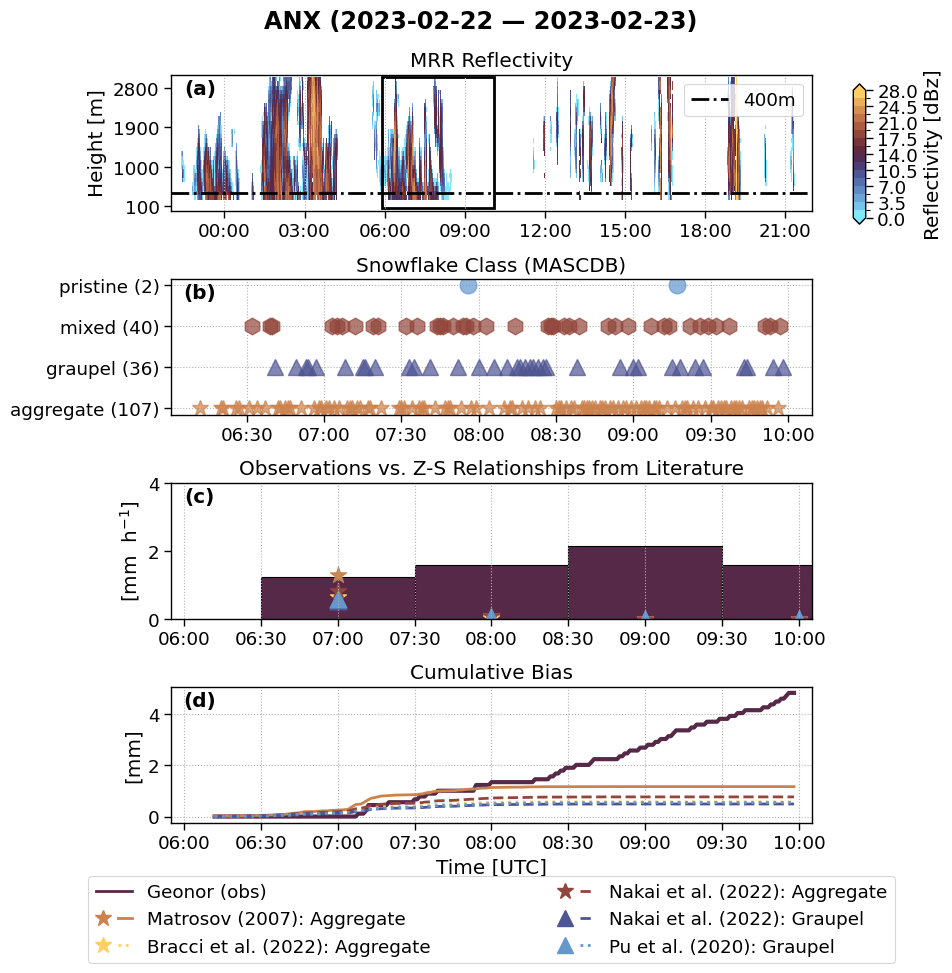

In [18]:
time_vals = fct.date2num(ds_day['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(4, 1, figsize=(8.27, 7.014/3*4), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_day['Ze'].transpose('range','time'), x=time_vals, y=ds_day['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_day['Ze'].attrs['units']}]", cbar_pos=[cbar_left, cbar_top -0 *cbar_step, cbar_width, cbar_height])
axs[0].hlines(4., ds_day.time.values[0], ds_day.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')
axs[0].set_xlim([day_start, day_end])


# create a rectangle path
rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_day)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_day['snowflake_class_name'].where(df_day['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)
    

axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# -----------

# c)
dt = "event_offset"
for var, var_c in colors.items():
    df_sec = df[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    precip = df_sec[var].resample('1H').sum()
    if var == 'Geonor':
        axs[2].bar(precip.index, precip, width=np.timedelta64(60,'m'), align='center', color=var_c[0], edgecolor='k', label=var_c[1])
    else: 
        axs[2].scatter(precip.index, precip, marker=var_c[3], color=var_c[0], s=150, edgecolor=var_c[0])
axs[2].set_ylabel("[mm  h$^{-1}$]")
axs[2].set_ylim([0, 4])
axs[2].set_xlim([x_start, x_end])


# -----------

# d)
for var, var_c in colors.items():
    df_sec = df[dt].loc[slice(xmin, xmax)]
    precip = df_day[var].fillna(0).cumsum()
    if var == 'Geonor':
        linewidth = 3
    else:
        linewidth = 2
    axs[3].plot(precip.index, precip, color=var_c[0], label=var_c[1], linestyle=var_c[2], linewidth=linewidth)
axs[3].set_ylabel("[mm]")
# axs[3].set_ylim([0, 4])
axs[3].set_xlim([x_start, x_end])
# -----------

# pairing: either (marker,line) or (line,marker) depending on visual preference
legend_items = [
    geonor_line,
    (matro_mark, matro_line),
    (bracci_mark, bracci_line),
    (nakaiA_mark, nakaiA_line),
    (nakaiG_mark, nakaiG_line), 
    (Pu_mark, Pu_line)
]
bb = (fig.subplotpars.left -0.1, fig.subplotpars.bottom-0.15, 
fig.subplotpars.right-fig.subplotpars.left + 0.2,.1)

axs[3].legend(
    handles = legend_items,
    labels  = legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    bbox_to_anchor=bb, mode="expand", loc="lower left",
    ncol=2, borderaxespad=0., bbox_transform=fig.transFigure
)



date_form = DateFormatter("%H:%M")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Observations vs. Z-S Relationships from Literature", "Cumulative Bias"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3: 
        ax.yaxis.grid(ls=':')
    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
axs[-1].set(xlabel="Time [UTC]")
axs[-1].yaxis.grid(ls=':')

fig.suptitle(f"{site.split('.')[0]} ({ds_day.time.dt.date[0].values} — {ds_day.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.91, hspace=0.5, )

# save image to png
plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_20230222_20230223.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

### Graupel case: 2023-03-08 12:00 to 2023-03-09 06:00

In [19]:
date = '20230308'

day_start = pd.Timestamp(f"{date} 12:00:00")
# day_end = day_start + pd.Timedelta(hours=23, minutes=59)
day_end = day_start + pd.Timedelta(hours=24)
xmin = day_start + pd.Timedelta(hours=5)
xmax = day_start + pd.Timedelta(hours=8)

ds_day = ds_23.sel(time=slice(day_start, day_end))
dt = '1min'
df_day = df[dt].loc[slice(xmin, xmax)]

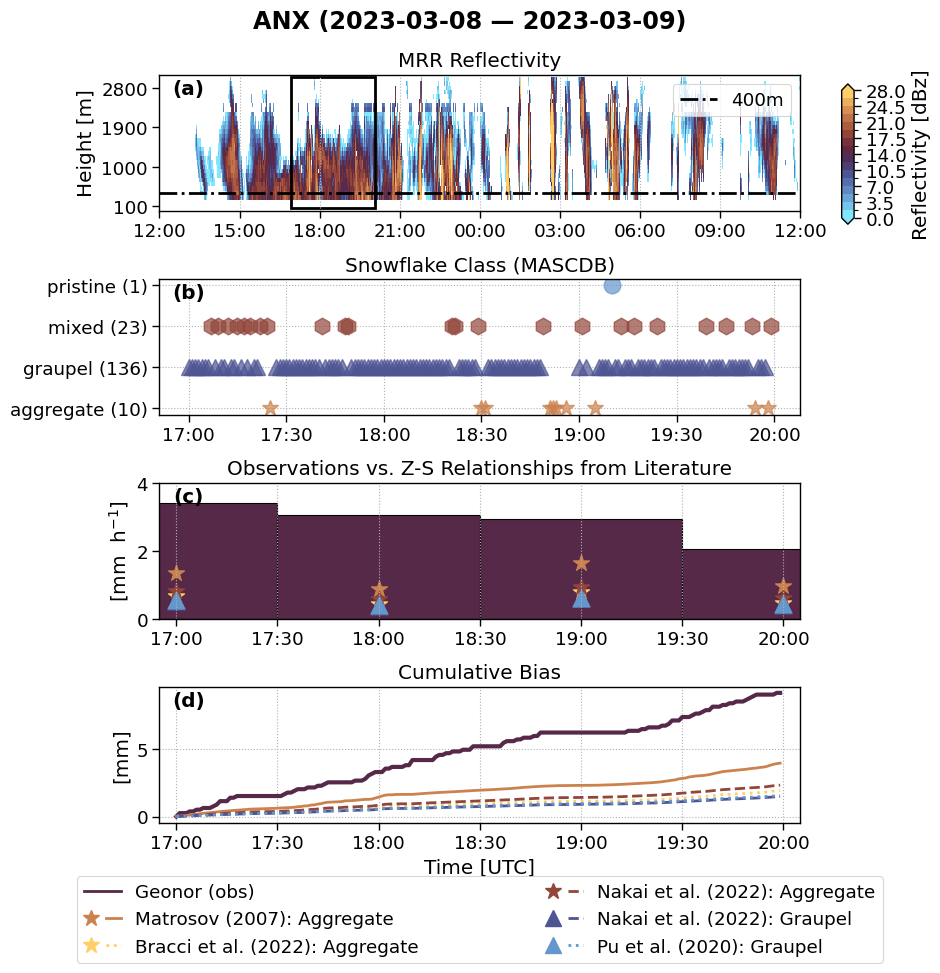

In [20]:
time_vals = fct.date2num(ds_day['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(4, 1, figsize=(8.27, 7.014/3*4), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_day['Ze'].transpose('range','time'), x=time_vals, y=ds_day['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_day['Ze'].attrs['units']}]", cbar_pos=[cbar_left, cbar_top -0 *cbar_step, cbar_width, cbar_height])
axs[0].hlines(4., ds_day.time.values[0], ds_day.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')
axs[0].set_xlim([day_start, day_end])


# create a rectangle path
rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_day)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_day['snowflake_class_name'].where(df_day['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)
    

axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# -----------

# c)
dt = "event_offset"
for var, var_c in colors.items():
    df_sec = df[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    precip = df_sec[var].resample('1H').sum()
    if var == 'Geonor':
        axs[2].bar(precip.index, precip, width=np.timedelta64(60,'m'), align='center', color=var_c[0], edgecolor='k', label=var_c[1])
    else: 
        axs[2].scatter(precip.index, precip, marker=var_c[3], color=var_c[0], s=150, edgecolor=var_c[0])
axs[2].set_ylabel("[mm  h$^{-1}$]")
axs[2].set_ylim([0, 4])
axs[2].set_xlim([x_start, x_end])


# -----------

# d)
for var, var_c in colors.items():
    df_sec = df[dt].loc[slice(xmin, xmax)]
    precip = df_day[var].fillna(0).cumsum()
    if var == 'Geonor':
        linewidth = 3
    else:
        linewidth = 2
    axs[3].plot(precip.index, precip, color=var_c[0], label=var_c[1], linestyle=var_c[2], linewidth=linewidth)
axs[3].set_ylabel("[mm]")
# axs[3].set_ylim([0, 4])
axs[3].set_xlim([x_start, x_end])
# -----------

# pairing: either (marker,line) or (line,marker) depending on visual preference
legend_items = [
    geonor_line,
    (matro_mark, matro_line),
    (bracci_mark, bracci_line),
    (nakaiA_mark, nakaiA_line),
    (nakaiG_mark, nakaiG_line), 
    (Pu_mark, Pu_line)
]
bb = (fig.subplotpars.left -0.1, fig.subplotpars.bottom-0.15, 
fig.subplotpars.right-fig.subplotpars.left + 0.2,.1)

axs[3].legend(
    handles = legend_items,
    labels  = legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    bbox_to_anchor=bb, mode="expand", loc="lower left",
    ncol=2, borderaxespad=0., bbox_transform=fig.transFigure
)



date_form = DateFormatter("%H:%M")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Observations vs. Z-S Relationships from Literature", "Cumulative Bias"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3: 
        ax.yaxis.grid(ls=':')
    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
axs[-1].set(xlabel="Time [UTC]")
axs[-1].yaxis.grid(ls=':')

fig.suptitle(f"{site.split('.')[0]} ({ds_day.time.dt.date[0].values} — {ds_day.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.91, hspace=0.5, )

# save image to png

# save image to png
plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_20230308_20230309.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

### Seasonal overview
use minuetly data

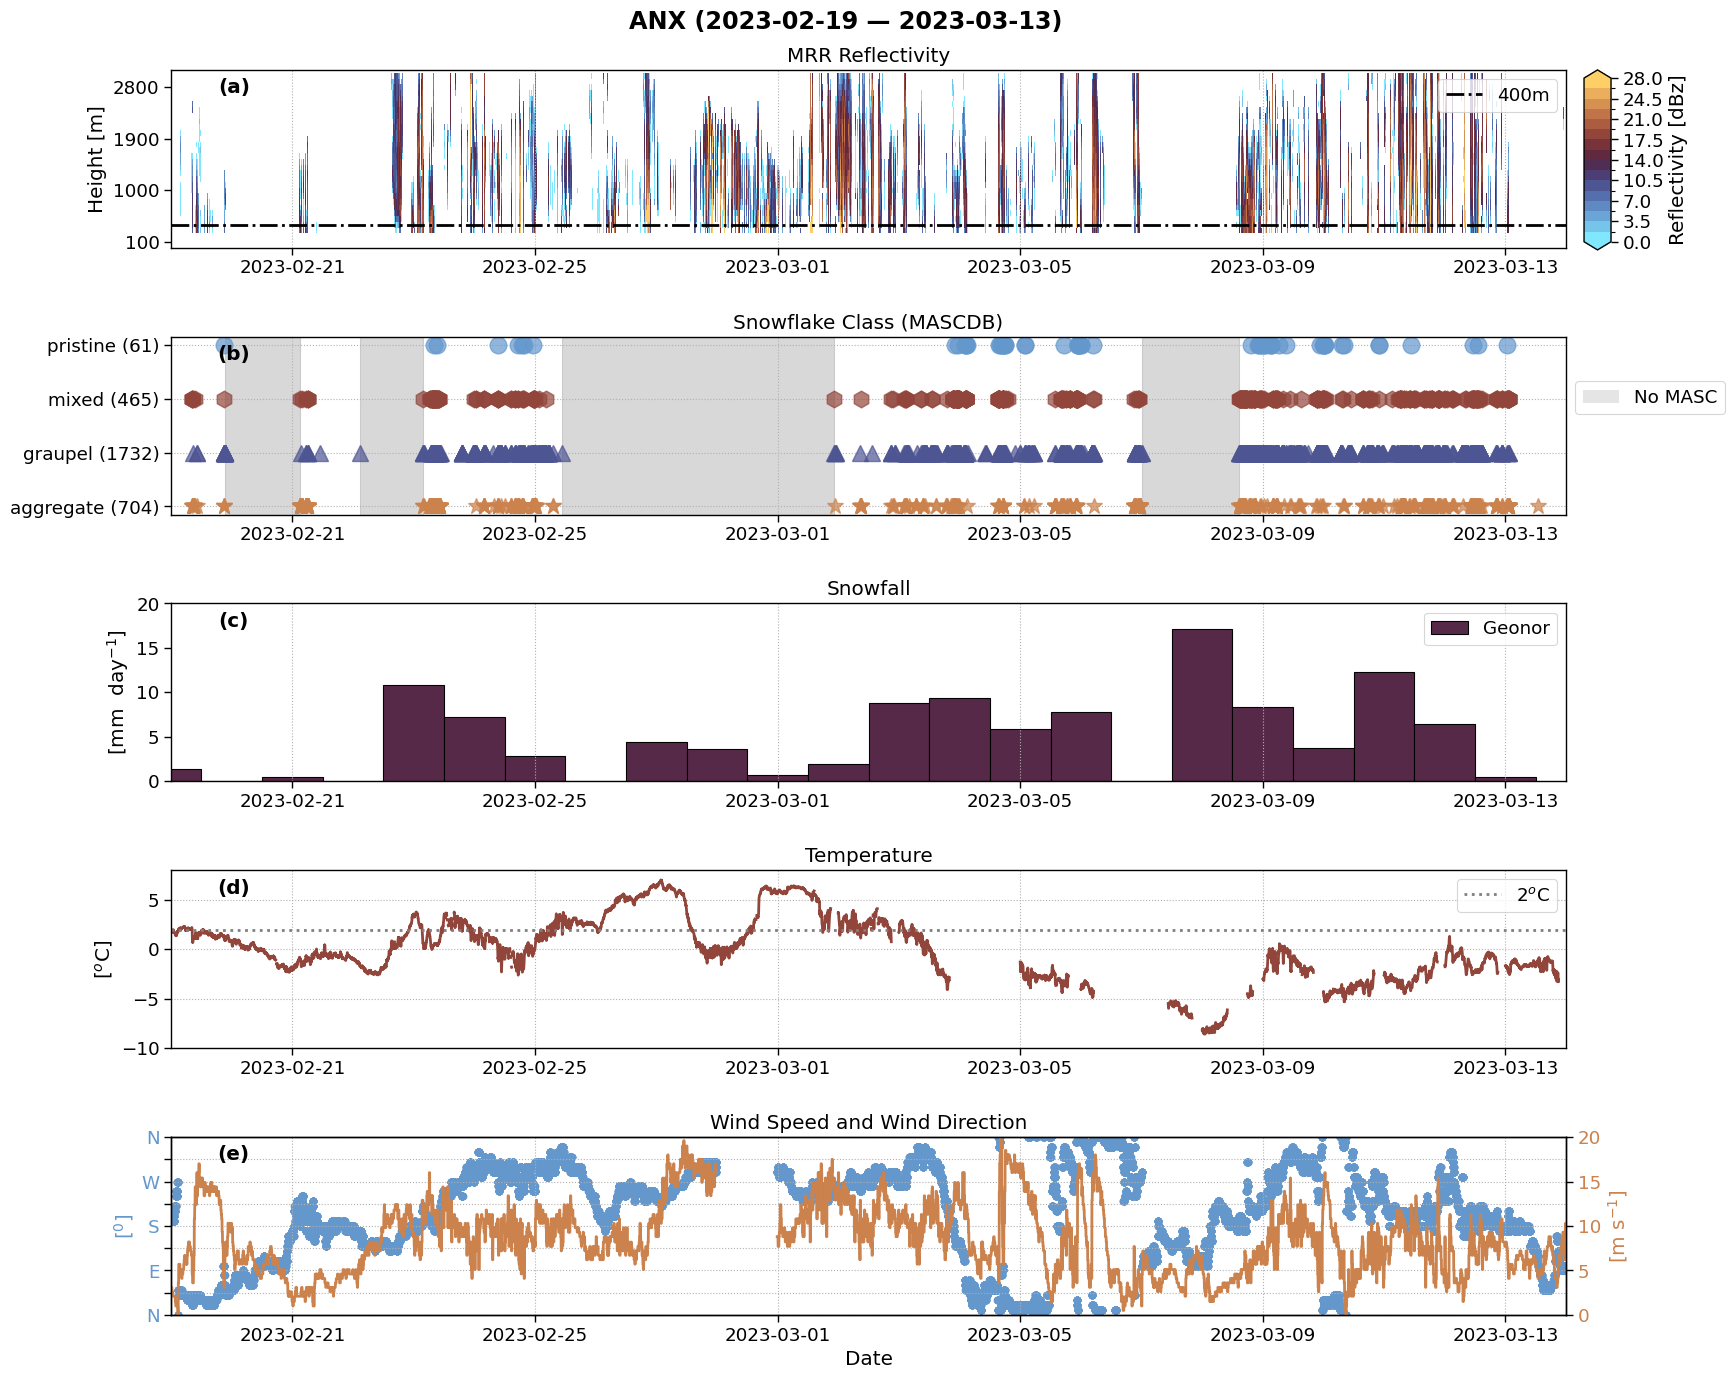

In [21]:
dt = '1min'
day_start = pd.Timestamp("2023-02-19 00:00:00")
day_end = pd.Timestamp("2023-03-13 23:59:00")

ds_season = ds_23.sel(time=slice(day_start, day_end))
df_season = df[dt].loc[slice(day_start, day_end)]
df_season_no_sf_class = df_no_sf_class[dt].loc[slice(day_start, day_end)]

# get the “no MASC available” timestamps
all_times = df_season_no_sf_class.index
masc_times = df_season.index

# Example threshold
threshold = pd.Timedelta('1440min')

# Step 1: sort (just to be safe)
masc_times = masc_times.sort_values()
# Step 2: compute the gaps between consecutive MASC timestamps
deltat = masc_times.to_series().diff()
# Step 3: find where the gap exceeds threshold
gap_starts = masc_times[deltat > threshold]          # first timestamp *after* a long gap
gap_ends = gap_starts - deltat[deltat > threshold]       # last timestamp *before* the gap

gaps = list(zip(gap_ends, gap_starts))

time_vals = fct.date2num(ds_season['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(5, 1, figsize=(18, 15), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_season['Ze'].transpose('range','time'), x=time_vals, y=ds_season['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_season['Ze'].attrs['units']}]", cbar_pos=[cbar_left-0.04, 0.82, cbar_width, cbar_height/5*4])
axs[0].hlines(4., ds_season.time.values[0], ds_season.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')


# # create a rectangle path
# rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
# axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_season)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_season['snowflake_class_name'].where(df_season['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)

for g_start, g_end in gaps:
    axs[1].axvspan(g_start, g_end, color='grey', alpha=0.3)    

axs[1].legend(handles=[
    Patch(facecolor='grey', alpha=0.2, label="No MASC"),
], bbox_to_anchor=(1.0, 0.8))
axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# -----------

# c)
precip = df_season_no_sf_class['Geonor'].resample('24H').sum()
# precip = ds_season['Geonor'].resample(time='24H').sum()
axs[2].bar(precip.index, precip, width=np.timedelta64(60*24,'m'), align='center', color=colors['Geonor'][0], edgecolor='k', label='Geonor')
 
axs[2].set_ylabel("[mm  day$^{-1}$]")
axs[2].legend()
axs[2].set_ylim([0, 20])
# -----------

# d)
temp = ds_season['air_temperature']
axs[3].plot(temp.time.values, temp, color=fct.custom_colors['mixed'])
axs[3].hlines(2., temp.time.values[0], temp.time.values[-1], colors='grey', linestyles=':', label='$2^{o}$C')
axs[3].set_ylabel("[$^{o}$C]")
axs[3].set_ylim([-10, 8])
axs[3].legend()
# -----------

# e)
wd = ds_season['wind_direction']
axs[4].scatter(wd.time.values, wd, color=fct.custom_colors['pristine'])
axs[4].set_ylabel('[$^{0}$]', color=fct.custom_colors['pristine'])
axs[4].tick_params(axis='y', labelcolor=fct.custom_colors['pristine'])
axs[4].set_ylim(0,360)
axs[4].set_yticks(np.arange(0,365,45))
axs[4].set_yticklabels(['N', '', 'E', '' , 'S', '', 'W', '', 'N'])

ws = ds_season['wind_speed']
ax2 = axs[4].twinx()
ax2.plot(ws.time.values, ws, color=fct.custom_colors['aggregate'])
ax2.set_ylabel('[m s$^{-1}$]', color=fct.custom_colors['aggregate'])
ax2.tick_params(axis='y', labelcolor=fct.custom_colors['aggregate'])
ax2.set_ylim(0,20)




date_form = DateFormatter("%Y-%m-%d")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Snowfall", "Temperature", "Wind Speed and Wind Direction"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3 or i == 4:
        ax.yaxis.grid(ls=':')
    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
    ax.set_xlim([day_start, day_end])


axs[-1].set(xlabel="Date")
axs[4].yaxis.grid(ls=':')

fig.suptitle(f"{site.split('.')[0]} ({ds_season.time.dt.date[0].values} — {ds_season.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.94, hspace=0.5, )

# save image to png
plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_2Tm_WD_WS_{site}_20230219_20230313.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [22]:
directions_deg = df_season_no_sf_class['wind_direction']
def mean_wind_direction(directions_deg):
    # Convert degrees → radians
    directions_rad = np.deg2rad(directions_deg)

    # Compute mean of unit circle components
    sin_mean = np.mean(np.sin(directions_rad))
    cos_mean = np.mean(np.cos(directions_rad))

    # Compute the circular mean
    mean_rad = np.arctan2(sin_mean, cos_mean)

    # Convert radians → degrees
    mean_deg = np.rad2deg(mean_rad)

    # Ensure result is in [0, 360)
    print((mean_deg % 360).round(0))

mean_wind_direction(directions_deg)

215.0


In [23]:
gaps

[(Timestamp('2023-02-19 21:30:00'), Timestamp('2023-02-21 02:57:00')),
 (Timestamp('2023-02-22 02:55:00'), Timestamp('2023-02-23 03:33:00')),
 (Timestamp('2023-02-25 10:46:00'), Timestamp('2023-03-01 22:25:00')),
 (Timestamp('2023-03-07 00:05:00'), Timestamp('2023-03-08 14:40:00'))]

In [24]:
np.asarray(counts).sum()

np.int64(2962)

In [25]:
print(df_season[df_season['snowflake_class_name'] == 'mixed']['air_temperature'].mean().round(2),
      df_season[df_season['snowflake_class_name'] == 'mixed']['wind_speed'].mean().round(1),
      )
mean_wind_direction(df_season[df_season['snowflake_class_name'] == 'mixed']['wind_direction'])

-1.69 8.9
211.0


In [26]:
temp_ = ds_season['air_temperature'].sel(time=slice('2023-02-27', '2023-02-28'))
# temp_[temp_> 2].dropna()
temp_.where(temp_ >2).dropna('time').values
temp_.max().values.round(2), temp_.min().values.round(2)

(np.float64(6.99), np.float64(-1.55))

In [27]:
df_season_no_sf_class['Geonor'].loc[slice('2023-02-27', '2023-02-28')].resample('24H').sum().sum()

np.float64(8.0677666666667)

In [28]:
df_season_no_sf_class['Geonor'].resample('24H').sum().mean()

np.float64(4.952421739130469)

In [29]:
ds_season['wind_speed'].sel(time=slice('2023-03-03', '2023-03-14')).mean().values
df_season_no_sf_class['Geonor'].loc[slice('2023-03-03', '2023-03-14')].sum().sum()

np.float64(80.44613333333395)

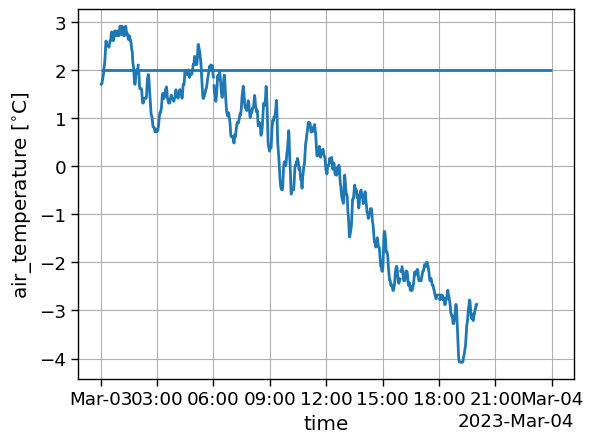

In [30]:
temp_ = ds_season['air_temperature'].sel(time=slice('2023-03-03', '2023-03-03'))
temp_.plot()
plt.hlines(y=2., xmin=temp_.time[0], xmax=temp_.time[-1])
plt.grid()

In [31]:
df_season_no_sf_class['air_temperature'].mean(), df_season_no_sf_class['wind_speed'].mean()

(np.float64(-1.6436094009431899), np.float64(7.700420444094075))

In [32]:
df_season_no_sf_class['Geonor'].resample('24H').sum().idxmax(), df_season_no_sf_class['Geonor'].resample('24H').sum().max()

(Timestamp('2023-03-08 00:00:00'), np.float64(17.100599999999602))

### Particle Type Frequency per Wind direction
use event-based data

In [33]:
dt = 'event_offset'
day_start = pd.Timestamp("2023-02-19 00:00:00")
day_end = pd.Timestamp("2023-03-13 23:59:00")

ds_season = ds_23.sel(time=slice(day_start, day_end))
df_season = df[dt].loc[slice(day_start, day_end)]
df_season_nearest = df_nearest[dt].loc[slice(day_start, day_end)]
df_season_no_sf_class = df_no_sf_class[dt].loc[slice(day_start, day_end)]


In [34]:
def wind_sector(deg):
    if (deg >= 337.5) or (deg < 22.5):
        return 'N'
    elif 22.5 <= deg < 67.5:
        return 'NE'
    elif 67.5 <= deg < 112.5:
        return 'E'
    elif 112.5 <= deg < 157.5:
        return 'SE'
    elif 157.5 <= deg < 202.5:
        return 'S'
    elif 202.5 <= deg < 247.5:
        return 'SW'
    elif 247.5 <= deg < 292.5:
        return 'W'
    else:
        return 'NW'

direction_labels = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', ]

In [35]:
num_bins = len(direction_labels)
bin_width_deg = 360/num_bins
half_bin = bin_width_deg/2
bin_edges = np.linspace(-half_bin, 360-half_bin, num_bins+1)
bin_edges

array([-22.5,  22.5,  67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])

In [36]:
df_season['wind_direction_sector'] = pd.cut(df_season['wind_direction'], bins=bin_edges, labels=direction_labels, include_lowest=True)


In [37]:
#Group counts Compute Snowflake Frequencies per ( Wind Sector)
counts = df_season.groupby(['snowflake_class_name', 'wind_direction_sector']).size().reset_index(name='count')

# Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
pivot = counts.pivot_table(index=['wind_direction_sector'], columns='snowflake_class_name', values='count', fill_value=0)

pivot_plot = pivot.div(pivot.sum(axis=1), axis=0).T * 100
default_label = "% Frequency"
format = ".2f"
n_bins = 10
bounds = np.linspace(0, 100, n_bins +1)
cmap_base = cm.managua_r

cmaplist = [cmap_base(i/(n_bins -1)) for i in range(n_bins)]
custom_cmap = ListedColormap(cmaplist)
    
norm = BoundaryNorm(bounds, ncolors=custom_cmap.N)

In [38]:
print(dt)

event_offset


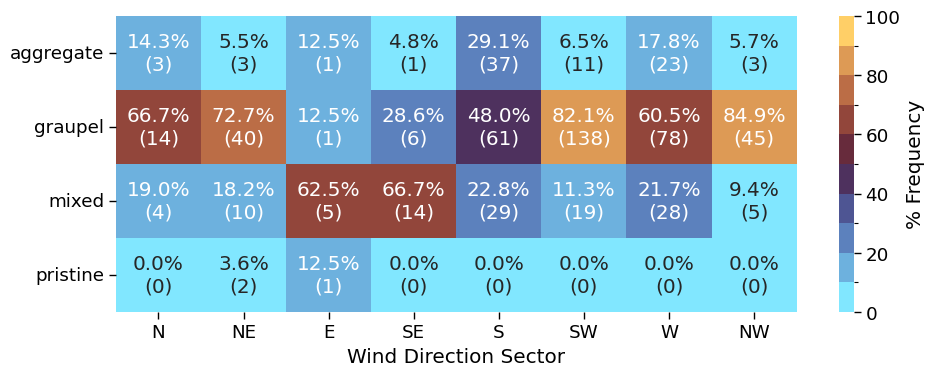

In [39]:
# Plot 
plt.figure(figsize=(10, 4))
annot_data = pivot_plot.round(1).astype(str) + "%\n(" + pivot.T.astype(int).astype(str) + ")"

ax = sns.heatmap(pivot_plot, annot=annot_data, fmt="", cmap=custom_cmap, norm=norm, cbar_kws={'label': default_label})

# Labeling
ax.set_xlabel("Wind Direction Sector")
ax.set_ylabel("")
plt.tight_layout()

# save image to png
plt.savefig(FIG_DIR + f"relative_sf_class_frequency_by_wind_sector_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [40]:
pivot_plot

wind_direction_sector,N,NE,E,SE,S,SW,W,NW
snowflake_class_name,,,,,,,,
aggregate,14.285714,5.454545,12.5,4.761905,29.133858,6.547619,17.829457,5.660377
graupel,66.666667,72.727273,12.5,28.571429,48.031496,82.142857,60.465116,84.905660
mixed,19.047619,18.181818,62.5,66.666667,22.834646,11.309524,21.705426,9.433962
pristine,0.000000,3.636364,12.5,0.000000,0.000000,0.000000,0.000000,0.000000


In [41]:
pivot.T.sum(axis=0), pivot.T.sum(axis=1)

(wind_direction_sector
 N      21.0
 NE     55.0
 E       8.0
 SE     21.0
 S     127.0
 SW    168.0
 W     129.0
 NW     53.0
 dtype: float64,
 snowflake_class_name
 aggregate     82.0
 graupel      383.0
 mixed        114.0
 pristine       3.0
 dtype: float64)

### CFAD per particle type
use event-based data

In [42]:
print(dt)

event_offset


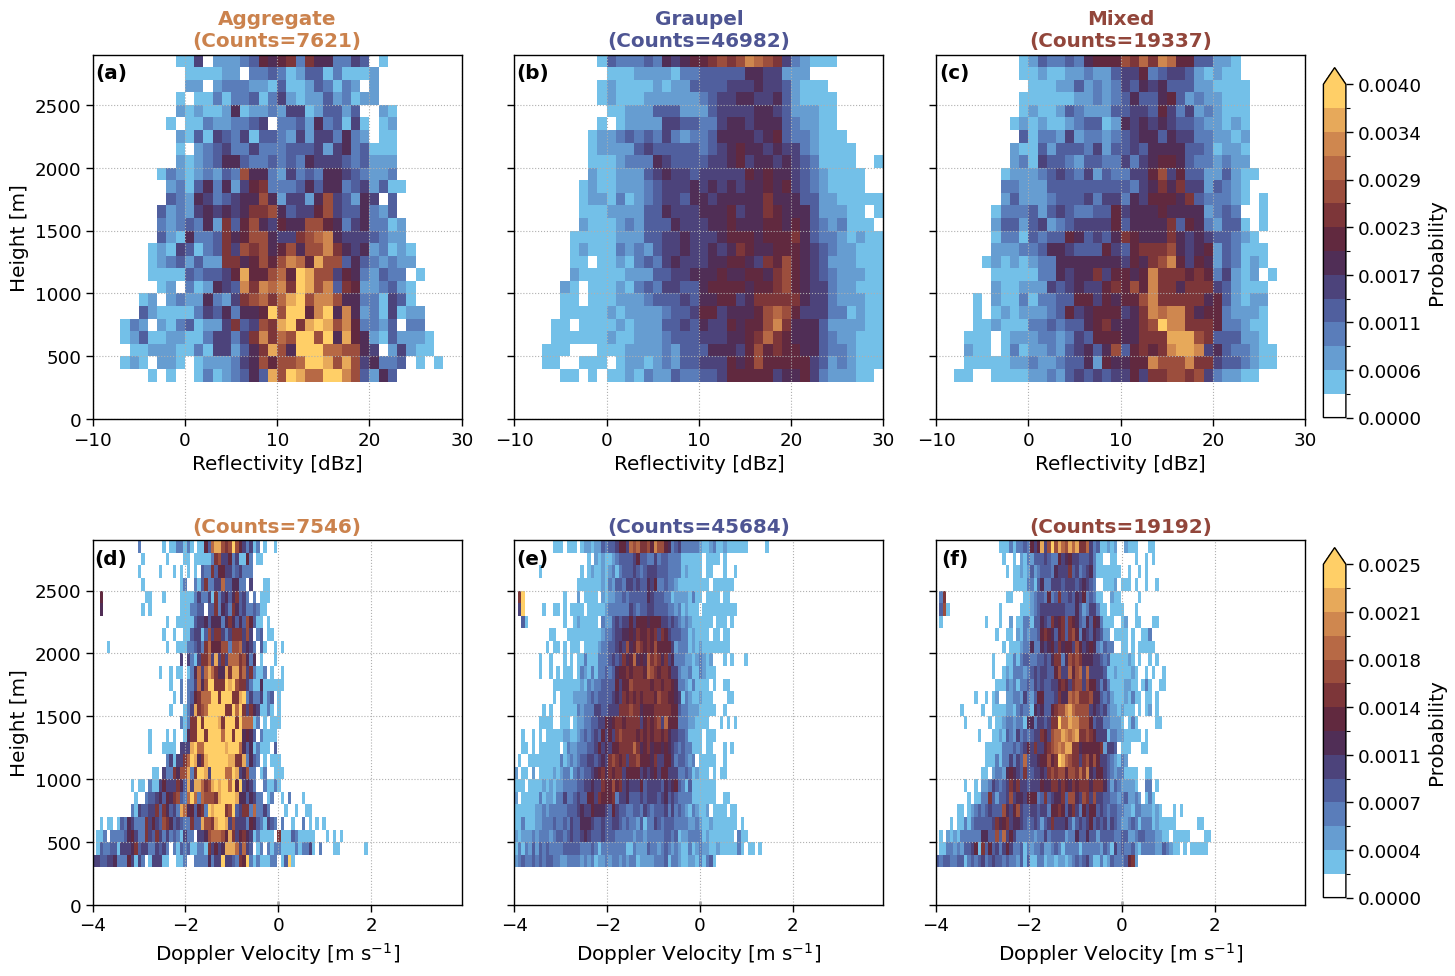

In [43]:
H_ze = dict()
H_ze_prob = dict()

H_w = dict()
H_w_prob = dict()

for sf_class, df_class in sf_class_dict[dt].items():
    
    _ds_in_dt = fct.get_ds_in_precip_event(sf_class_dict[dt][sf_class], ds_season)
    H_ze[sf_class], H_ze_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'Ze', 'height', fct.ze_bins, fct.height_bins)

    H_w[sf_class], H_w_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'W', 'height', fct.W_bins, fct.height_bins)

fct.plt_prob_agg_graupel_mixed(H_ze_prob, H_ze, H_w_prob, H_w)
# save image to png
plt.savefig(FIG_DIR + f"CFAD_aggregate_graupel_mixed_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

### Geonor vs. Literature precipitation scatter
use event-based data

In [44]:
print(dt)

event_offset


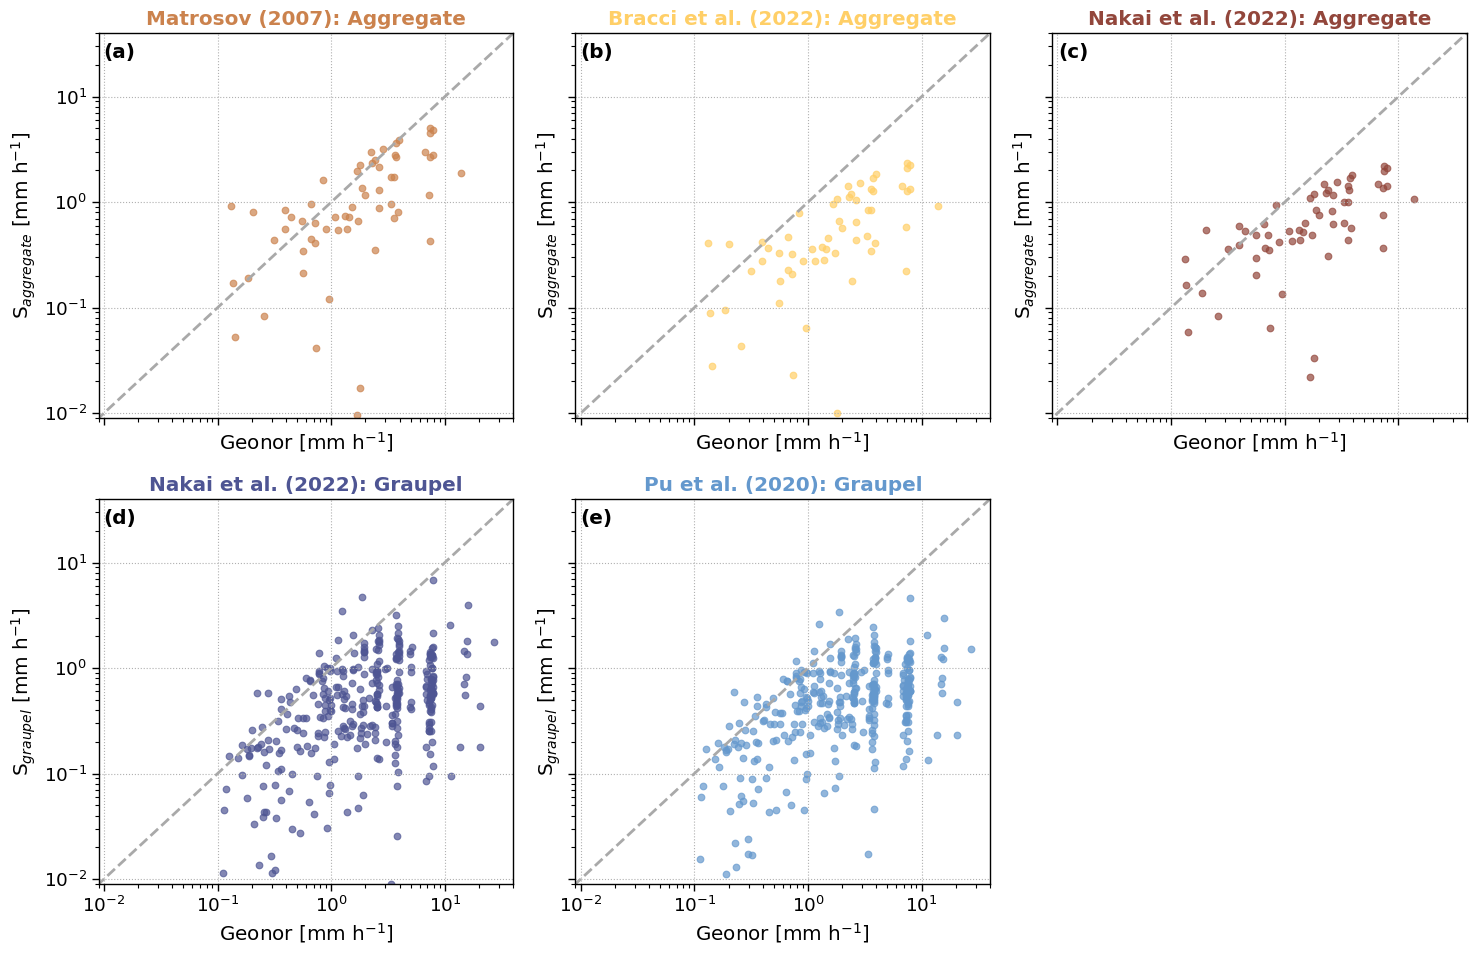

In [45]:
fct.plt_precip_scatter_literature(sf_class_dict[dt], title="")
# save image to png
plt.savefig(FIG_DIR + f"precip_vs_literature_precip_1min_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


### Cumulation season
Use the event-based data and the "nearest" crystal class data

In [46]:
print(dt)

event_offset


In [47]:
# Combine where MASC observes aggregate --> apply Z-S for aggregates, 
# where MASC observes graupel --> apply Z-S for graupel 
# For the combined Z-S relationship, use the "nearest" observe snowflake type (done in different notebook).
# For the "mixed" category, do the calculation twice, once where I assume mixed=graupel and another time where mixed=aggregate

# mixed = aggregate
mixed_aggregate=pd.DataFrame()
mixed_aggregate['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
mixed_aggregate['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_aggregate['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_aggregate['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

mixed_aggregate['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_aggregate['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_aggregate['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

# mixed = graupel
mixed_graupel=pd.DataFrame()
mixed_graupel['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
mixed_graupel['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_graupel['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_graupel['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

mixed_graupel['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_graupel['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_graupel['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

/tmp/ipykernel_2217215/1061410154.py:90: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


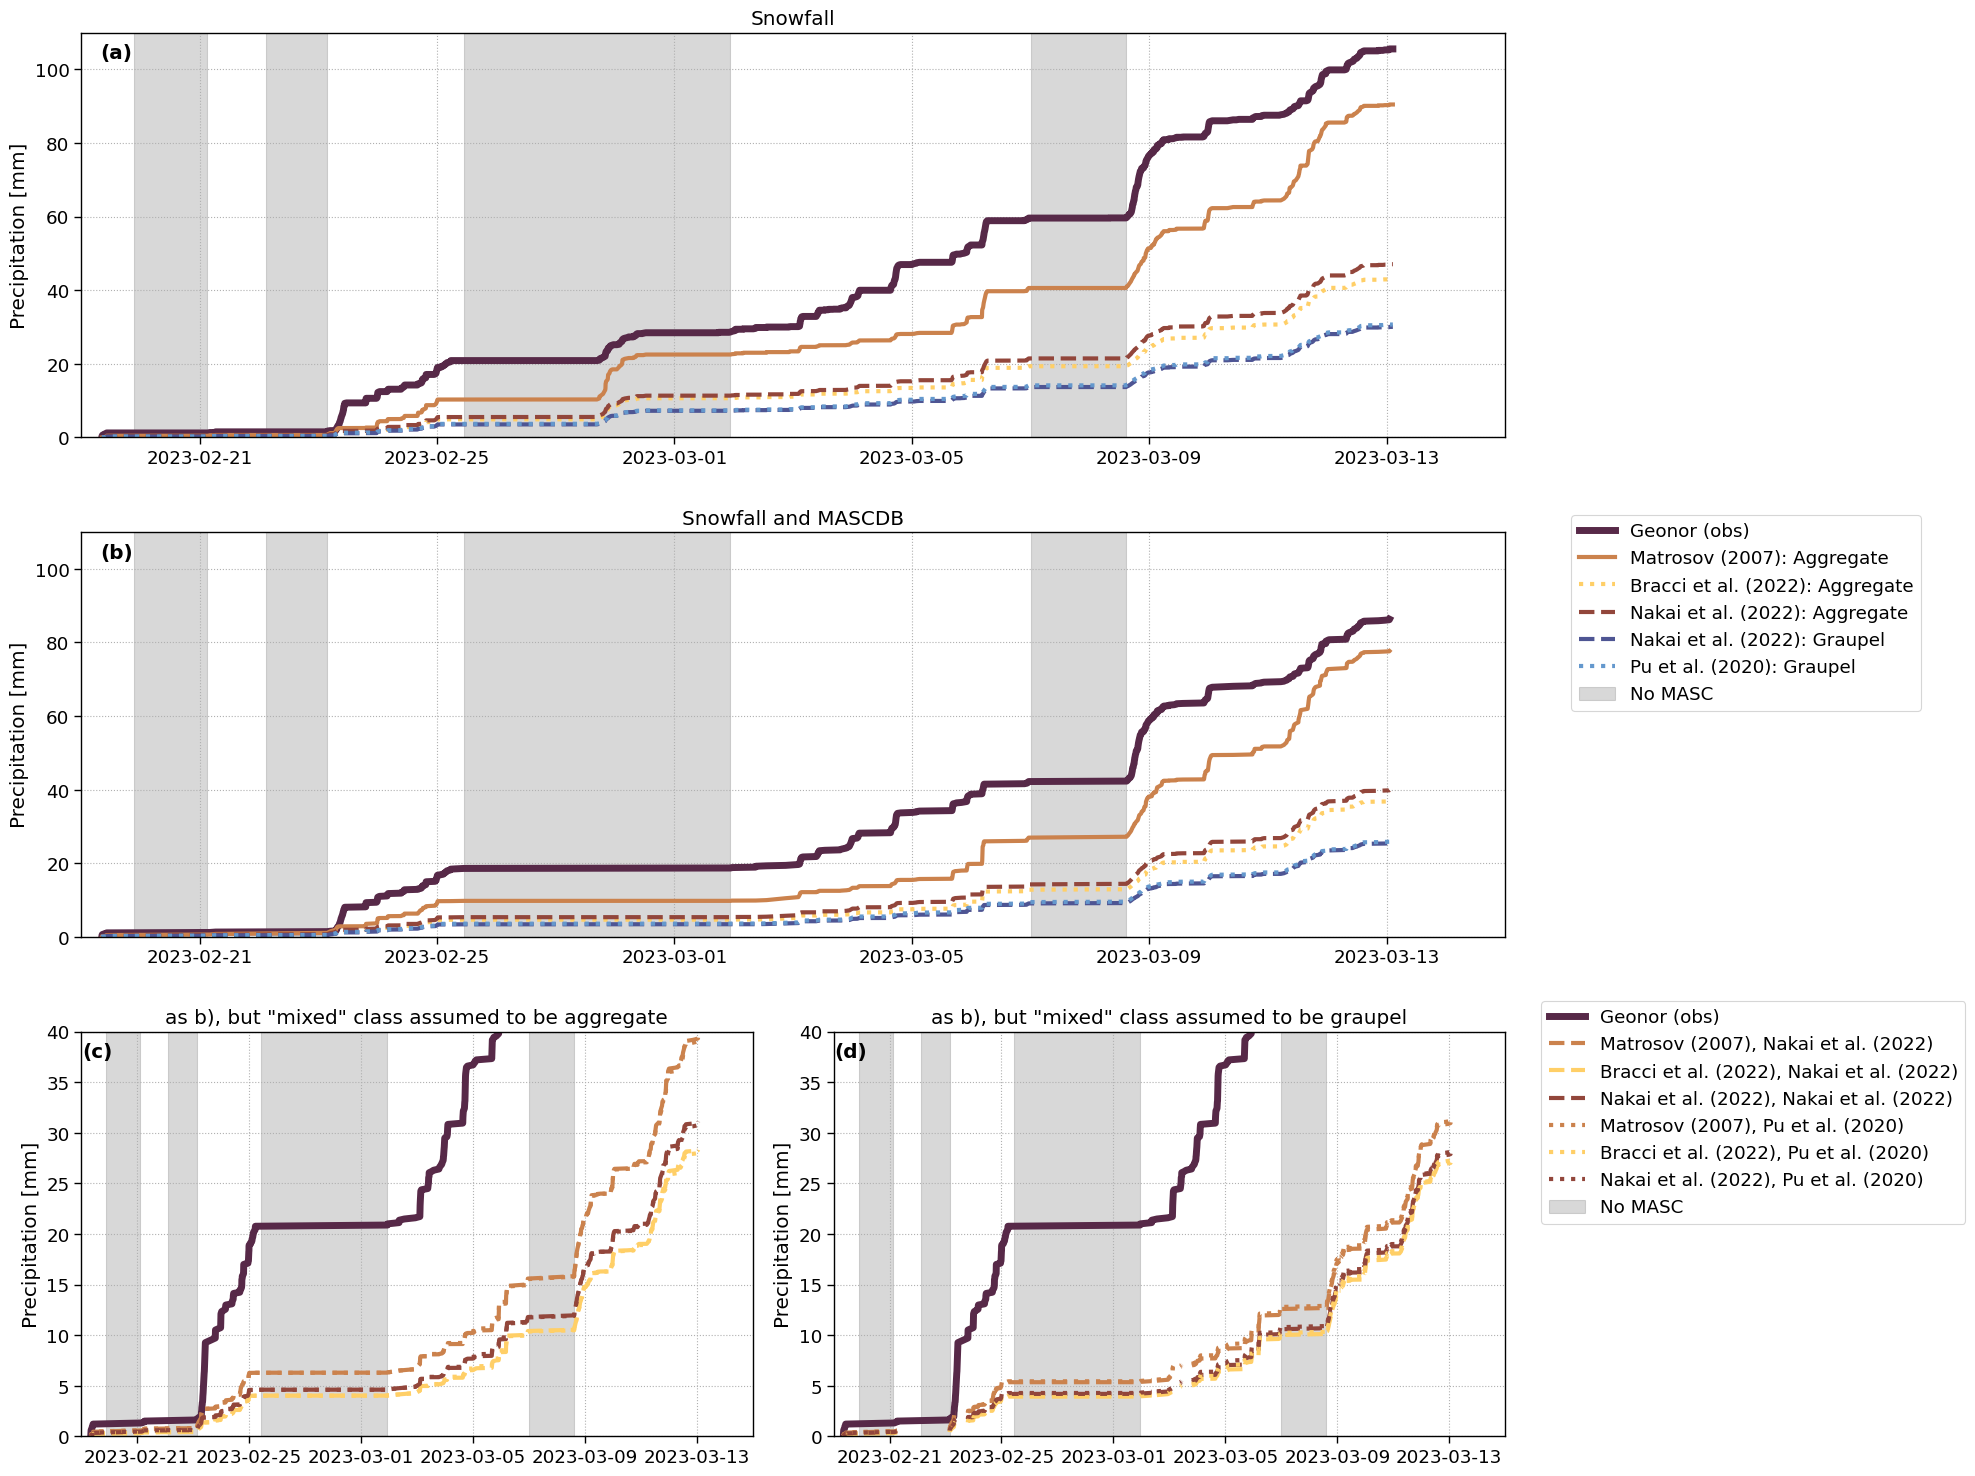

In [48]:
fig, axd = plt.subplot_mosaic([['first', 'first'],
                               ['second', 'second'],
                               ['left', 'right'],
                               ],
                              constrained_layout=True, figsize=(20,15), )#sharex=True)

# a)
for var, var_c in colors.items():
    if var == 'Geonor':
        linewidth = 5
    else: 
        linewidth = 3
    # precip2 = ds_season[var].cumsum()
    # axd['first'].plot(precip2.time.values, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
    precip = df_season_no_sf_class[var].cumsum()
    precip = precip.fillna(method='ffill')
    axd['first'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
axd['first'].set_ylim([0, 110])
# -----------

# b)
for var, var_c in colors.items():
    if var == 'Geonor':
        linewidth = 5
    else: 
        linewidth = 3
    precip = df_season[var].cumsum(skipna=True)
    precip = precip.fillna(method='ffill')
    axd['second'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
    # for t in no_masc_times:
    #     axd['left'].axvline(t, color="red", alpha=0.15, linewidth=6)
    # Shade gaps

axd['second'].set_ylim([0, 110])
# -----------

# c) and d)
for var, var_c in colors2.items():
    if var == 'Geonor_aggregate_graupel_only':
        linewidth = 5
    else:
        linewidth = 3
    precip = mixed_aggregate[var].cumsum(skipna=True)
    precip = precip.fillna(method='ffill')
    axd['left'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)
    

    precip2 = mixed_graupel[var].cumsum(skipna=True)
    axd['right'].plot(precip2.index, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)

axd['left'].set_ylim([0, 40])
axd['right'].set_ylim([0, 40])

# -----------




date_form = DateFormatter("%Y-%m-%d")
first = True
for (i, key), title in zip(enumerate(axd), ['Snowfall', 'Snowfall and MASCDB', 'as b), but "mixed" class assumed to be aggregate', 'as b), but "mixed" class assumed to be graupel']):
    axd[key].set(xlabel= "", title=title)
    axd[key].text(0.025, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = axd[key].transAxes)
    axd[key].xaxis.grid(which='both', ls=':')
    axd[key].yaxis.grid(which='both', ls=':')
    axd[key].tick_params(axis='x', labelrotation=0)
    plt.setp(axd[key].get_xticklabels(), horizontalalignment='center')
    axd[key].xaxis_date()
    axd[key].xaxis.set_major_formatter(date_form)
    axd[key].set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-15' 00:00:00")])
    axd[key].set_ylabel("Precipitation [mm]")
    first = True
    for g_start, g_end in gaps:
        if first:
            axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='No MASC')
            first = False
        else:
            axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='_nolegend_')



axd['second'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
axd['right'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
# axd['right'].legend(loc='center left', bbox_to_anchor=(1, 0.5))
# axd['second'].legend(handles=[
#     Patch(facecolor='red', alpha=0.2, label="No MASC observation"),
# ])


plt.tight_layout()
# save image to png
plt.savefig(FIG_DIR + f'cumsum_precip_{site}_20230219_20230313.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)